In [18]:
from gauche.dataloader import MolPropLoader

loader = MolPropLoader()
loader.load_benchmark("Photoswitch")

# We use the fragprints representations
loader.featurize('ecfp_fragprints')
X = loader.features
y = loader.labels

Found 13 invalid labels [nan nan nan nan nan nan nan nan nan nan nan nan nan] at indices [41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 158]
To turn validation off, use dataloader.read_csv(..., validate=False).


In [2]:
import numpy as np
import time
import torch
import warnings
import botorch

from botorch.acquisition import LogExpectedImprovement
from botorch.exceptions import BadInitialCandidatesWarning
from botorch.exceptions import InputDataWarning
from botorch.fit import fit_gpytorch_mll
from sklearn.model_selection import train_test_split

def optimize_acqf_and_get_observation(acq_func:botorch.acquisition, 
                                      heldout_inputs:torch.Tensor, 
                                      heldout_outputs:torch.Tensor):
    # Loop over the discrete set of points to evaluate the acquisition function at.
    acq_vals = []
    for i in range(len(heldout_outputs)):
        acq_vals.append(acq_func(heldout_inputs[i].unsqueeze(-2)))

    # Observe new values
    acq_vals = torch.stack(acq_vals)
    best_idx = torch.argmax(acq_vals)
    new_x = heldout_inputs[best_idx].unsqueeze(-2) # add batch dimension
    new_obj = heldout_outputs[best_idx].unsqueeze(-1) # add output dimension

    # Delete the selected input and value from the heldout
    heldout_inputs = torch.cat((heldout_inputs[:best_idx], heldout_inputs[best_idx+1:]), axis=0)
    heldout_outputs = torch.cat((heldout_outputs[:best_idx], heldout_outputs[best_idx+1:]), axis=0)

    return new_x, new_obj, heldout_inputs, heldout_outputs

In [3]:
X.shape

(392, 2133)

In [ ]:
from crda_gp.bo import initialize_model

N_TRIALS = 20
holdout_set_size = 0.95
N_ITERS = 20
verbose = False

warnings.filterwarnings('ignore', category=BadInitialCandidatesWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=InputDataWarning)

best_observed_all_ei = []

for trial in range(1, N_TRIALS + 1):

    print(f"\nTrial {trial:>2} of {N_TRIALS}", end="")
    best_observed_ei = []

    # Generate initial training data initialize model
    train_x_ei, heldout_x_ei, train_y_ei, heldout_y_ei = train_test_split(X, y, test_size=holdout_set_size, random_state=trial)
    best_observed_value_ei = torch.tensor(np.max(train_y_ei))

    # Convert numpy arrays to PyTorch tensors and flatten the label vectors
    train_x_ei = torch.tensor(train_x_ei.astype(np.float64))
    heldout_x_ei = torch.tensor(heldout_x_ei.astype(np.float64))
    train_y_ei = torch.tensor(train_y_ei.astype(np.float64))
    heldout_y_ei = torch.tensor(heldout_y_ei.astype(np.float64))

    model_ei, mll_ei = initialize_model(train_x=train_x_ei, train_obj=train_y_ei)

    best_observed_ei.append(best_observed_value_ei)

    for iteration in range(1, N_ITERS + 1):

        t0 = time.time()

        # fit the model
        fit_gpytorch_mll(mll=mll_ei)

        # Use analytic acquisition function for batch size of 1.
        LogEI = LogExpectedImprovement(model=model_ei, best_f=(train_y_ei.to(train_y_ei)).max())

        

In [ ]:
from scipy.stats import qmc
from sklearn.metrics.pairwise import cosine_similarity

def optimize_acqf_and_get_observation(acq_func:botorch.acquisition, 
                                      heldout_inputs:torch.Tensor, 
                                      heldout_outputs:torch.Tensor,
                                      dims:int=2133,
                                      upper_bound:int=10):
    # Loop over the discrete set of points to evaluate the acquisition function at.
    sampler = qmc.Sobol(d=dims)
    samples = sampler.random(100)

    lower = np.zeros(dims)
    upper = np.random.uniform(low=upper_bound, high=upper_bound, size=dims)

    samples = qmc.scale(samples, lower, upper)

    acq_vals = []
    for i in range(len(samples)):
        acq_vals.append(acq_func(samples[i].unsqueeze(-2)))

    # Observe new values
    acq_vals = torch.stack(acq_vals)
    best_idx = torch.argmax(acq_vals)

    similarity_score = []
    for j in range(len(heldout_inputs)):
        similarity_score.append(cosine_similarity([samples[best_idx]], [heldout_inputs[j]]))

    similarity_idx = torch.argmax(similarity_score)
    candidate = heldout_inputs[similarity_idx].unsqueeze(-2)

    

    new_x = heldout_inputs[best_idx].unsqueeze(-2) # add batch dimension
    new_obj = heldout_outputs[best_idx].unsqueeze(-1) # add output dimension

    # Delete the selected input and value from the heldout
    heldout_inputs = torch.cat((heldout_inputs[:best_idx], heldout_inputs[best_idx+1:]), axis=0)
    heldout_outputs = torch.cat((heldout_outputs[:best_idx], heldout_outputs[best_idx+1:]), axis=0)

    return new_x, new_obj, heldout_inputs, heldout_outputs

In [22]:
X[0]

array([0, 0, 0, ..., 0, 0, 0], shape=(2133,))

In [23]:
np.zeros(2133)

array([0., 0., 0., ..., 0., 0., 0.], shape=(2133,))

In [24]:
np.random.uniform(low=10, high=10, size=2133)


array([10., 10., 10., ..., 10., 10., 10.], shape=(2133,))

In [26]:
sampler = qmc.Sobol(d=2133)
samples = sampler.random(100)
samples[0]

C:\Users\bandarua\AppData\Local\Temp\1\ipykernel_16448\810232980.py:2: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  samples = sampler.random(100)


array([0.49326019, 0.02815565, 0.85439878, ..., 0.05938746, 0.79365442,
       0.73255731], shape=(2133,))

In [181]:
def TinyCRDA(X: torch.Tensor,
             y: torch.Tensor,
             model: botorch.models.SingleTaskGP,
             perturb_idx: list[int]=[1,3],
             p:float=0.1,
             M:int=1):
    np.random.seed(42)
    model.eval()

    with torch.no_grad():
        pred_mean = model.posterior(X).mean

    residual_noise = y - pred_mean

    # print(f"Starting the Loop")
    for i in range(M):
        # print(f"Sample: {i}")
        x_new = X.clone()
        delta_pos = np.random.uniform(0, p)
        delta_neg = np.random.uniform(-p, 0)

        mask = perturb_idx < 0

        x_new[mask] *= (1 + delta_pos)
        x_new[~mask] *= (1 + delta_neg)

        # print(f"x_new shape: {x_new.shape}")

        with torch.no_grad():
            y_new = model.posterior(x_new).mean

        residual_noise = residual_noise.squeeze()
        y_new += residual_noise

    X_aug, y_aug = x_new, y_new

    return X_aug, y_aug

In [182]:
from crda_gp.bo import initialize_model

best_observed_ei = []
holdout_set_size = 0.95


# Generate initial training data initialize model
train_x_ei, heldout_x_ei, train_y_ei, heldout_y_ei = train_test_split(X, y, test_size=holdout_set_size, random_state=0)
best_observed_value_ei = torch.tensor(np.max(train_y_ei))

# Convert numpy arrays to PyTorch tensors and flatten the label vectors
train_x_ei = torch.tensor(train_x_ei.astype(np.float64))
heldout_x_ei = torch.tensor(heldout_x_ei.astype(np.float64))
train_y_ei = torch.tensor(train_y_ei.astype(np.float64))
heldout_y_ei = torch.tensor(heldout_y_ei.astype(np.float64))

model_ei, mll_ei = initialize_model(train_x=train_x_ei, train_obj=train_y_ei)

In [183]:
# Loop over the discrete set of points to evaluate the acquisition function at.
dims=2133
upper_bound = np.random.uniform(low=10, high=10, size=dims)
lower_bound = np.zeros(shape=dims)

acq_func = LogExpectedImprovement(model_ei, train_y_ei.to(train_y_ei).max())


sampler = qmc.Sobol(d=dims)
samples = sampler.random(100)

lower = np.zeros(dims)
upper = np.random.uniform(low=upper_bound, high=upper_bound, size=dims)
samples = torch.tensor(qmc.scale(samples, lower, upper))
acq_vals = []
for i in range(len(samples)):
    acq_vals.append(acq_func(samples[i].unsqueeze(-2)))

# Observe new values
acq_vals = torch.stack(acq_vals)
best_idx = torch.argmax(acq_vals)

C:\Users\bandarua\AppData\Local\Temp\1\ipykernel_16448\1764231626.py:10: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  samples = sampler.random(100)


In [184]:
best_idx

tensor(73)

In [185]:
acq_vals[best_idx]

tensor([-1.4039], dtype=torch.float64, grad_fn=<SelectBackward0>)

In [186]:
heldout_inputs = heldout_x_ei
similarity_score = []
round
for j in range(len(heldout_inputs)):
    similarity_score.append(cosine_similarity([samples[best_idx]], [heldout_inputs[j]]))
    similarity_idx = torch.argmax(torch.tensor(similarity_score))
    
candidate = heldout_inputs[similarity_idx].unsqueeze(-2)
perturb_idx = samples[best_idx] - candidate

In [187]:
candidate

tensor([[0., 0., 0.,  ..., 0., 0., 0.]], dtype=torch.float64)

In [188]:
samples[best_idx]

tensor([7.8768, 1.3752, 8.5266,  ..., 7.2873, 3.5805, 5.1643],
       dtype=torch.float64)

In [189]:
perturb_idx.squeeze()

tensor([7.8768, 1.3752, 8.5266,  ..., 7.2873, 3.5805, 5.1643],
       dtype=torch.float64)

In [206]:
from scipy.stats import qmc
from sklearn.metrics.pairwise import cosine_similarity

def optimize_acqf_and_get_observation(acq_func:botorch.acquisition, 
                                      heldout_inputs:torch.Tensor, 
                                      heldout_outputs:torch.Tensor,
                                      model:botorch.models.SingleTaskGP,
                                      values:np.ndarray,
                                      probabilities:np.ndarray,
                                      dims:int=2133,
                                      upper_bound:int=10,
                                      n_cand:int=1000):
    # Loop over the discrete set of points to evaluate the acquisition function at.
    samples  = np.empty((n_cand, dims))

    for k in range(dims):
        samples[:, k] = np.random.choice(
            values,
            size=n_cand,
            p=probabilities
        )
    samples = torch.tensor(samples)
    acq_vals = []
    for i in range(len(samples)):
        acq_vals.append(acq_func(samples[i].unsqueeze(-2)))

    # Observe new values
    acq_vals = torch.stack(acq_vals)
    best_idx = torch.argmax(torch.tensor(acq_vals))

    similarity_score = []
    for j in range(len(heldout_inputs)):
        similarity_score.append(cosine_similarity([samples[best_idx]], [heldout_inputs[j]]))

    similarity_idx = torch.argmax(torch.tensor(similarity_score))
    candidate = heldout_inputs[similarity_idx].unsqueeze(-2)

    perturb_idx = samples[best_idx] - candidate

    x_new, y_new = TinyCRDA(candidate, heldout_outputs[similarity_idx].unsqueeze(-2), model, perturb_idx)

    return x_new, y_new

In [207]:
values, counts = np.unique(X, return_counts=True)
num_features = X.shape[0] * X.shape[1] 
probabilities = counts / num_features

In [208]:
from crda_gp.bo import initialize_model

N_TRIALS = 20
holdout_set_size = 0.95
N_ITERS = 20
verbose = False

warnings.filterwarnings('ignore', category=BadInitialCandidatesWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=InputDataWarning)
warnings.filterwarnings('ignore', category=UserWarning)

best_observed_all_ei = []

for trial in range(1, N_TRIALS + 1):

    print(f"\nTrial {trial:>2} of {N_TRIALS}", end="")
    best_observed_ei = []

    # Generate initial training data initialize model
    train_x_ei, heldout_x_ei, train_y_ei, heldout_y_ei = train_test_split(X, y, test_size=holdout_set_size, random_state=trial)
    best_observed_value_ei = torch.tensor(np.max(train_y_ei))

    # Convert numpy arrays to PyTorch tensors and flatten the label vectors
    train_x_ei = torch.tensor(train_x_ei.astype(np.float64))
    heldout_x_ei = torch.tensor(heldout_x_ei.astype(np.float64))
    train_y_ei = torch.tensor(train_y_ei.astype(np.float64))
    heldout_y_ei = torch.tensor(heldout_y_ei.astype(np.float64))

    model_ei, mll_ei = initialize_model(train_x=train_x_ei, train_obj=train_y_ei)

    best_observed_ei.append(best_observed_value_ei)

    for iteration in range(1, N_ITERS + 1):

        t0 = time.time()

        # fit the model
        fit_gpytorch_mll(mll=mll_ei)

        # Use analytic acquisition function for batch size of 1.
        LogEI = LogExpectedImprovement(model=model_ei, best_f=(train_y_ei.to(train_y_ei)).max())

        new_x_ei, new_obj_ei = optimize_acqf_and_get_observation(LogEI,
                                                                 heldout_inputs=heldout_x_ei,
                                                                 heldout_outputs=heldout_y_ei,
                                                                 values=values,
                                                                 probabilities=probabilities,
                                                                 model=model_ei)

        train_x_ei = torch.cat([train_x_ei, new_x_ei])
        train_y_ei = torch.cat([train_y_ei, new_obj_ei])

        best_value_ei = torch.max(new_obj_ei, best_observed_ei[-1])
        best_observed_ei.append(best_value_ei.squeeze())

        model_ei, mll_ei = initialize_model(train_x_ei, train_y_ei, model_ei.state_dict())

        t1 = time.time()

        if verbose:
            print(f"\nBatch {iteration:>2} | best_value (EI): {best_value_ei} | time: {t1 - t0:4.2f}", end="")
        else:
            print(".", end="")

    best_observed_all_ei.append(torch.hstack(best_observed_ei))


Trial  1 of 20....................
Trial  2 of 20....................
Trial  3 of 20....................
Trial  4 of 20....................
Trial  5 of 20....................
Trial  6 of 20....................
Trial  7 of 20....................
Trial  8 of 20....................
Trial  9 of 20....................
Trial 10 of 20....................
Trial 11 of 20....................
Trial 12 of 20....................
Trial 13 of 20....................
Trial 14 of 20....................
Trial 15 of 20....................
Trial 16 of 20....................
Trial 17 of 20....................
Trial 18 of 20....................
Trial 19 of 20....................
Trial 20 of 20....................

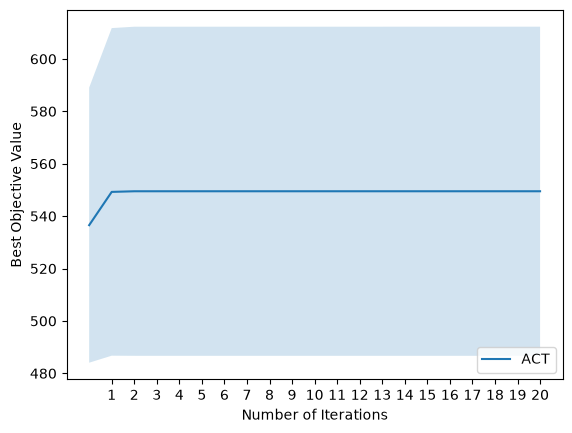

In [209]:
from crda_gp.bo import plot_confidence
plot_confidence(best_observed=best_observed_all_ei)